<a href="https://colab.research.google.com/github/ThammishettiSathvika/Advanced-Pedestrian-Detection/blob/main/Advanced_Pedestrian_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving b30.3.jpeg to b30.3.jpeg


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 161MB/s]


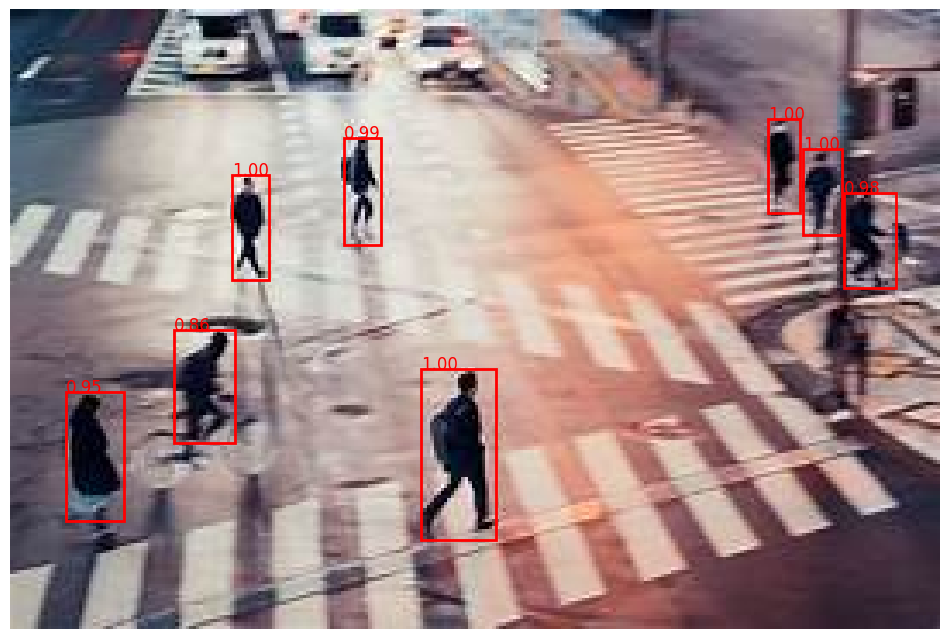

In [1]:
!pip install torch torchvision matplotlib
import torch
import torchvision
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()  # Upload an image from your system
image_path = list(uploaded.keys())[0]  # Get the image name
image = Image.open(image_path).convert("RGB")  # Open the image
transform = transforms.Compose([
    transforms.ToTensor()  # Convert image to PyTorch tensor
])
image_tensor = transform(image)
# Load the pretrained Faster R-CNN model
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)
model.eval()  # Set model to evaluation mode
# Run the model on the image
with torch.no_grad():
    prediction = model([image_tensor])
# Show image and draw boxes
plt.figure(figsize=(12, 10))
plt.imshow(image)

# Loop through predictions and draw bounding boxes with scores > 0.7
for i, box in enumerate(prediction[0]['boxes']):
    score = prediction[0]['scores'][i].item()
    label = prediction[0]['labels'][i].item()

    if score > 0.7 and label == 1:  # Class 1 is 'person' in COCO dataset
        box = box.cpu().numpy()
        plt.gca().add_patch(plt.Rectangle(
            (box[0], box[1]),
            box[2] - box[0],
            box[3] - box[1],
            edgecolor='red',
            linewidth=2,
            fill=False
        ))
        plt.text(box[0], box[1], f'{score:.2f}', color='red', fontsize=12)

plt.axis('off')
plt.show()


